In [4]:

import os

print(os.listdir("../data/data/raw/apnea-ecg"))

['a01.apn', 'a01.dat', 'a01.hea', 'a01.qrs', 'a02.apn', 'a02.dat', 'a02.hea', 'a03.apn', 'a03.dat', 'a03.hea', 'a04.apn', 'a04.dat', 'a04.hea', 'a05.apn', 'a05.dat', 'a05.hea', 'a06.apn', 'a06.dat', 'a06.hea', 'a07.apn', 'a07.dat', 'a07.hea', 'a08.apn', 'a08.dat', 'a08.hea', 'a09.apn', 'a09.dat', 'a09.hea', 'a10.apn', 'a10.dat', 'a10.hea', 'a11.apn', 'a11.dat', 'a11.hea', 'a12.apn', 'a12.dat', 'a12.hea', 'a13.apn', 'a13.dat', 'a13.hea', 'a14.apn', 'a14.dat', 'a14.hea', 'a15.apn', 'a15.dat', 'a15.hea']


In [5]:
%pip install numpy pandas matplotlib scikit-learn wfdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report

print("Libraries imported successfully")

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.
Libraries imported successfully


In [6]:
import wfdb

record = wfdb.rdrecord("../data/data/raw/apnea-ecg/a01")

print("Signal shape:", record.p_signal.shape)
print("Sampling frequency:", record.fs)
print("Channels:", record.sig_name)

Signal shape: (2957000, 1)
Sampling frequency: 100
Channels: ['ECG']


In [56]:
ecg = record.p_signal[:, 0]

print("ECG shape:", ecg.shape)
print("First 10 samples:")
print(ecg[:10])

ECG shape: (3056000,)
First 10 samples:
[-0.135 -0.11  -0.08  -0.08  -0.06  -0.08  -0.08  -0.115 -0.1   -0.12 ]


In [57]:
# Check ECG sampling frequency and annotation alignment

print("Sampling frequency:", record.fs)
print("ECG duration (minutes):",
      len(record.p_signal) / record.fs / 60)

ann = wfdb.rdann(str(DATA_DIR / "a01"), "apn")

print("\nFirst 15 annotation symbols:")
print(ann.symbol[:15])

print("\nFirst 15 annotation times (seconds):")
print(ann.sample[:15] / record.fs)

print("\nDifferences between annotation times (seconds):")
print(np.diff(ann.sample[:15]) / record.fs)

print("\nUnique annotation symbols and counts:")
print(np.unique(ann.symbol, return_counts=True))

Sampling frequency: 100
ECG duration (minutes): 509.3333333333333

First 15 annotation symbols:
['N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'A', 'A']

First 15 annotation times (seconds):
[  0.  60. 120. 180. 240. 300. 360. 420. 480. 540. 600. 660. 720. 780.
 840.]

Differences between annotation times (seconds):
[60. 60. 60. 60. 60. 60. 60. 60. 60. 60. 60. 60. 60. 60.]

Unique annotation symbols and counts:
(array(['A', 'N'], dtype='<U1'), array([470,  19]))


In [8]:
fs = record.fs

print("Sampling frequency:", fs)

Sampling frequency: 100


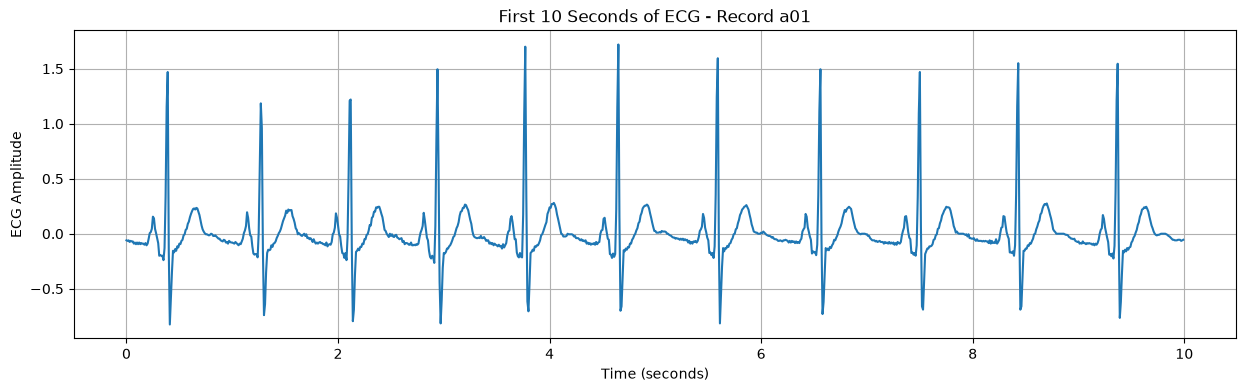

In [9]:
seconds = 10

samples = int(seconds * fs)

plt.figure(figsize=(15, 4))

plt.plot(
    np.arange(samples) / fs,
    ecg[:samples]
)

plt.xlabel("Time (seconds)")
plt.ylabel("ECG Amplitude")
plt.title("First 10 Seconds of ECG - Record a01")
plt.grid()

plt.show()

In [10]:

import wfdb

annotation = wfdb.rdann("../data/data/raw/apnea-ecg/a01", "apn")

print("Number of annotations:", len(annotation.sample))

print("First 20 annotation samples:")
print(annotation.sample[:20])

print("First 20 symbols:")
print(annotation.symbol[:20])


Number of annotations: 489
First 20 annotation samples:
[     0   6000  12000  18000  24000  30000  36000  42000  48000  54000
  60000  66000  72000  78000  84000  90000  96000 102000 108000 114000]
First 20 symbols:
['N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'A', 'A', 'A', 'A', 'A', 'A', 'A']


In [11]:
print("Sampling frequency:", record.fs)

print("\nFirst 20 annotation samples:")
print(annotation.sample[:20])

print("\nFirst 20 annotation times (seconds):")
print(annotation.sample[:20] / record.fs)

print("\nFirst 20 annotation symbols:")
print(annotation.symbol[:20])

Sampling frequency: 100

First 20 annotation samples:
[     0   6000  12000  18000  24000  30000  36000  42000  48000  54000
  60000  66000  72000  78000  84000  90000  96000 102000 108000 114000]

First 20 annotation times (seconds):
[   0.   60.  120.  180.  240.  300.  360.  420.  480.  540.  600.  660.
  720.  780.  840.  900.  960. 1020. 1080. 1140.]

First 20 annotation symbols:
['N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'A', 'A', 'A', 'A', 'A', 'A', 'A']


In [12]:
import numpy as np
import matplotlib.pyplot as plt

# ECG signal already loaded in 'record'
ecg = record.p_signal[:, 0]
fs = record.fs

print("Sampling frequency:", fs)
print("Number of samples:", len(ecg))

# Remove DC offset
ecg_centered = ecg - np.mean(ecg)

print("Original mean:", np.mean(ecg))
print("Mean after centering:", np.mean(ecg_centered))

Sampling frequency: 100
Number of samples: 2957000
Original mean: 0.0005639279675346633
Mean after centering: -1.275949248186044e-18


In [13]:
# Moving average window
window_seconds = 0.8
window = int(window_seconds * fs)

# Make sure window is odd
if window % 2 == 0:
    window += 1

# Estimate baseline
baseline = np.convolve(
    ecg_centered,
    np.ones(window) / window,
    mode='same'
)

# Remove baseline
ecg_detrended = ecg_centered - baseline

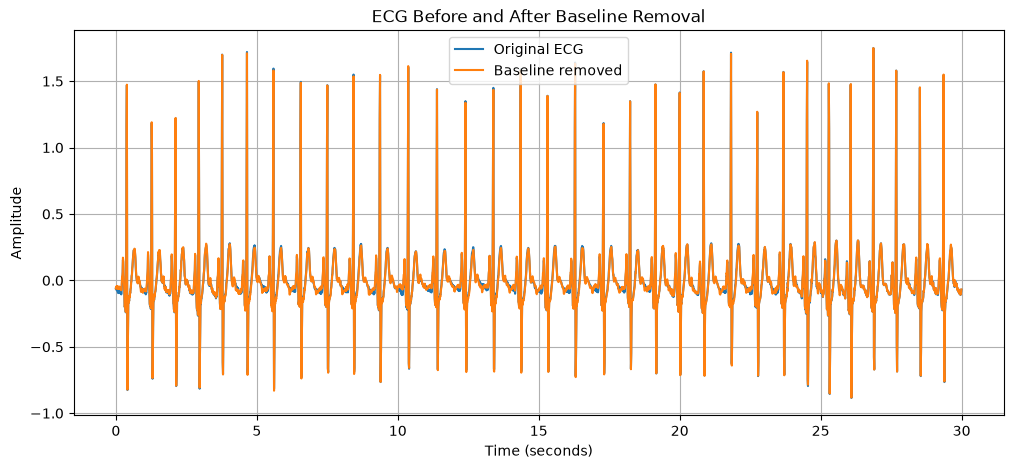

In [14]:
duration = 30
samples = int(duration * fs)

time = np.arange(samples) / fs

plt.figure(figsize=(12, 5))

plt.plot(time, ecg_centered[:samples], label="Original ECG")
plt.plot(time, ecg_detrended[:samples], label="Baseline removed")

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("ECG Before and After Baseline Removal")
plt.legend()
plt.grid()
plt.show()

In [15]:
# Low-pass moving average
lp_window_seconds = 0.08
lp_window = int(lp_window_seconds * fs)

if lp_window < 1:
    lp_window = 1

ecg_filtered = np.convolve(
    ecg_detrended,
    np.ones(lp_window) / lp_window,
    mode='same'
)

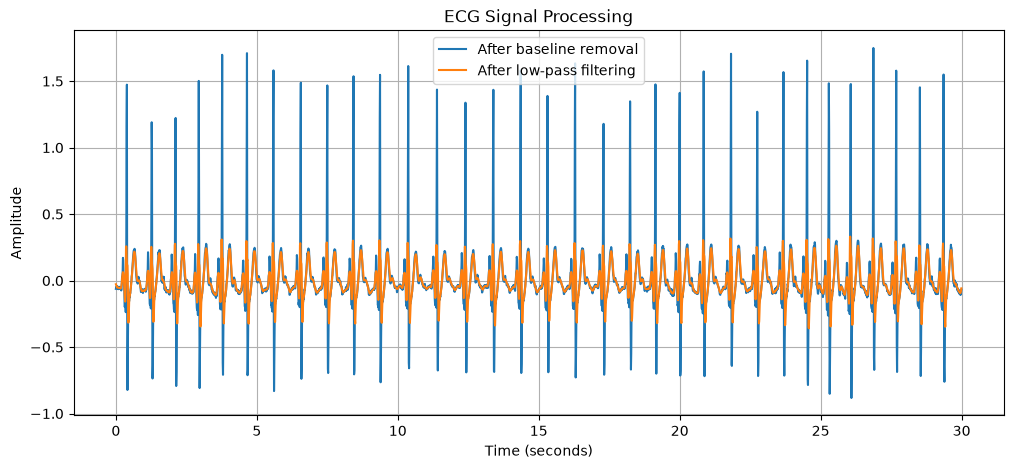

In [16]:
plt.figure(figsize=(12, 5))

plt.plot(time, ecg_detrended[:samples], label="After baseline removal")
plt.plot(time, ecg_filtered[:samples], label="After low-pass filtering")

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("ECG Signal Processing")
plt.legend()
plt.grid()
plt.show()

In [17]:
# R-peak detection using threshold + minimum distance

from scipy.signal import find_peaks
import numpy as np
import matplotlib.pyplot as plt

# Use the filtered ECG
signal = ecg_filtered

# Minimum distance between two heartbeats
# At least 0.5 seconds apart -> maximum ~120 BPM
min_distance = int(0.5 * fs)

# Set threshold based on the signal
threshold = np.mean(signal) + 0.5 * np.std(signal)

# Detect peaks
peaks, properties = find_peaks(
    signal,
    height=threshold,
    distance=min_distance
)

print("Number of detected R-peaks:", len(peaks))
print("First 20 R-peak samples:")
print(peaks[:20])

print("\nFirst 20 R-peak times (seconds):")
print(peaks[:20] / fs)

Number of detected R-peaks: 29820
First 20 R-peak samples:
[  37  126  210  292  375  463  557  654  748  841  935 1035 1137 1238
 1337 1434 1529 1627 1728 1822]

First 20 R-peak times (seconds):
[ 0.37  1.26  2.1   2.92  3.75  4.63  5.57  6.54  7.48  8.41  9.35 10.35
 11.37 12.38 13.37 14.34 15.29 16.27 17.28 18.22]


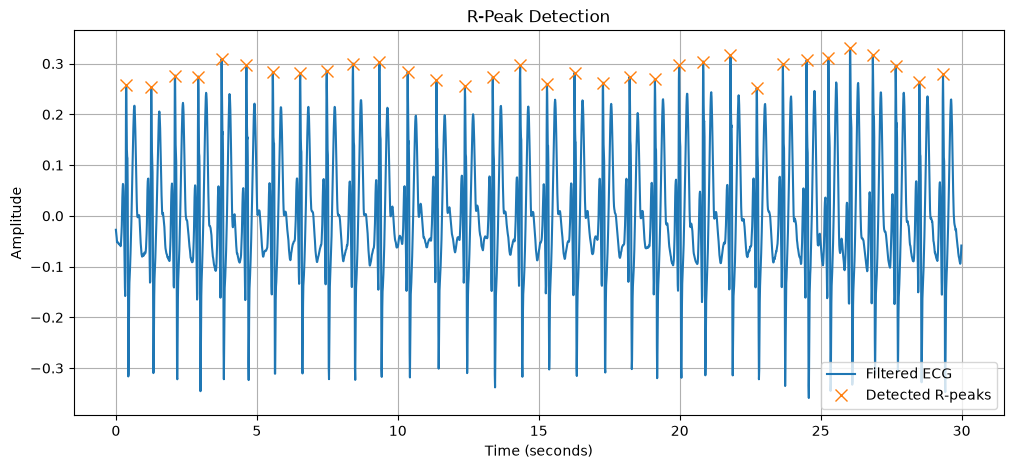

In [18]:
# Plot detected R-peaks over ECG

duration = 30
samples = int(duration * fs)

time = np.arange(samples) / fs

plt.figure(figsize=(12, 5))

plt.plot(time, signal[:samples], label="Filtered ECG")

# Only peaks within first 30 seconds
visible_peaks = peaks[peaks < samples]

plt.plot(
    visible_peaks / fs,
    signal[visible_peaks],
    "x",
    markersize=8,
    label="Detected R-peaks"
)

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("R-Peak Detection")
plt.legend()
plt.grid()
plt.show()

In [19]:
# Calculate RR intervals

rr_intervals = np.diff(peaks) / fs

print("Number of RR intervals:", len(rr_intervals))

print("\nFirst 20 RR intervals (seconds):")
print(rr_intervals[:20])

Number of RR intervals: 29819

First 20 RR intervals (seconds):
[0.89 0.84 0.82 0.83 0.88 0.94 0.97 0.94 0.93 0.94 1.   1.02 1.01 0.99
 0.97 0.95 0.98 1.01 0.94 0.9 ]


In [20]:
# Calculate instantaneous heart rate

heart_rate = 60 / rr_intervals

print("First 20 heart-rate values:")
print(heart_rate[:20], "BPM")

First 20 heart-rate values:
[67.41573034 71.42857143 73.17073171 72.28915663 68.18181818 63.82978723
 61.8556701  63.82978723 64.51612903 63.82978723 60.         58.82352941
 59.40594059 60.60606061 61.8556701  63.15789474 61.2244898  59.40594059
 63.82978723 66.66666667] BPM


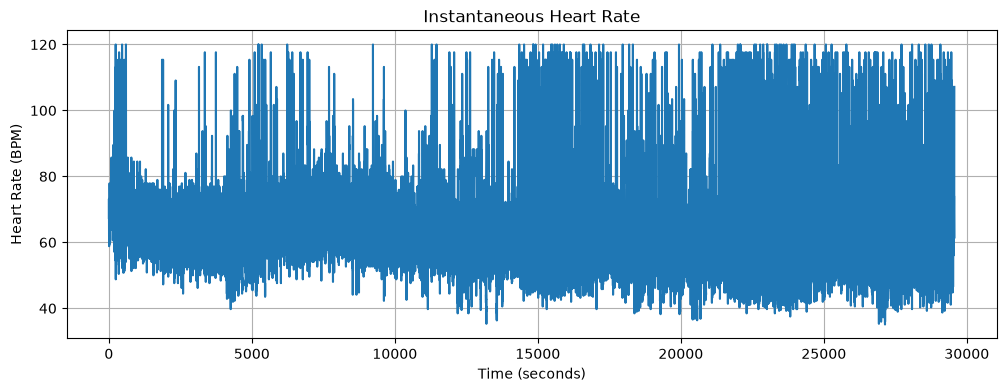

In [21]:
# Time corresponding to each RR interval
rr_time = peaks[1:] / fs

plt.figure(figsize=(12, 4))

plt.plot(rr_time, heart_rate)

plt.xlabel("Time (seconds)")
plt.ylabel("Heart Rate (BPM)")
plt.title("Instantaneous Heart Rate")
plt.grid()
plt.show()

In [58]:
# Step 1: Get the timestamp of each RR interval
rr_time = peaks[1:] / fs

# Step 2: Get annotation timestamps and labels
ann_time = annotation.sample / fs
ann_labels = np.array(annotation.symbol)


# Step 3: Find the annotation corresponding to each RR midpoint
rr_mid_time = (peaks[:-1] + peaks[1:]) / (2 * fs)

# Find the most recent annotation timestamp at or before each midpoint
minute_idx = np.searchsorted(ann_time, rr_mid_time, side="right") - 1

# Keep only RR intervals within the annotation time range
valid = (
    (minute_idx >= 0) &
    (minute_idx < len(ann_labels)) &
    (rr_mid_time < len(record.p_signal) / fs)
)

# Step 4: Create the labeled RR dataset
rr_labeled = pd.DataFrame({
    "time_sec": rr_mid_time[valid],
    "rr_interval_sec": rr_intervals[valid],
    "heart_rate_bpm": heart_rate[valid],
    "minute": minute_idx[valid],
    "label": ann_labels[minute_idx[valid]]
})

# Keep only the expected classes
rr_labeled = rr_labeled[
    rr_labeled["label"].isin(["A", "N"])
].reset_index(drop=True)

print("First 10 labeled RR intervals:")
display(rr_labeled.head(10))

print("\nDataset shape:", rr_labeled.shape)
print("\nLabel counts:")
print(rr_labeled["label"].value_counts())

print("\nLabel proportions:")
print(rr_labeled["label"].value_counts(normalize=True))


First 10 labeled RR intervals:


,time_sec,rr_interval_sec,heart_rate_bpm,minute,label
0,0.815,0.89,67.415730,0,N
1,1.680,0.84,71.428571,0,N
2,2.510,0.82,73.170732,0,N
3,3.335,0.83,72.289157,0,N
4,4.190,0.88,68.181818,0,N
5,5.100,0.94,63.829787,0,N
6,6.055,0.97,61.855670,0,N
7,7.010,0.94,63.829787,0,N
8,7.945,0.93,64.516129,0,N
9,8.880,0.94,63.829787,0,N



Dataset shape: (29819, 5)

Label counts:
label
A    22001
N     7818
Name: count, dtype: int64

Label proportions:
label
A    0.737818
N    0.262182
Name: proportion, dtype: float64


In [61]:
# Verify labels assigned to ECG windows

print("Total windows:", len(y))
print("Window shape:", X.shape)

print("\nLabel counts:")
print(pd.Series(y).map({
    0: "Normal",
    1: "Apnea"
}).value_counts())

print("\nWindows per patient and label:")
display(pd.crosstab(
    metadata["patient"],
    metadata["label"]
))

print("\nFirst 15 window labels:")
display(metadata.head(15))

Total windows: 1449
Window shape: (1449, 6000, 1)

Label counts:
Apnea     935
Normal    514
Name: count, dtype: int64

Windows per patient and label:


label,A,N
patient,,
a01,470,19
a03,246,273
a04,453,39
a05,276,177
a06,206,303
a07,321,189
a08,189,311
a09,381,114
a10,99,417



First 15 window labels:


,patient,minute,label
0,a01,0,N
1,a01,1,N
2,a01,2,N
3,a01,3,N
4,a01,4,N
5,a01,5,N
6,a01,6,N
7,a01,7,N
8,a01,8,N
9,a01,9,N


In [59]:
# Compare RR features between normal and apnea intervals

print("Feature statistics by class:")
display(
    rr_labeled.groupby("label")[
        ["rr_interval_sec", "heart_rate_bpm"]
    ].agg(["count", "mean", "std", "median"])
)

print("\nChecking for invalid values:")
print(
    rr_labeled[
        ["rr_interval_sec", "heart_rate_bpm"]
    ].isna().sum()
)

print("\nChecking for infinite values:")
print(
    np.isinf(
        rr_labeled[["rr_interval_sec", "heart_rate_bpm"]]
    ).sum()
)

Feature statistics by class:


rr_interval_sec                            heart_rate_bpm             \
                count      mean       std median          count       mean   
label                                                                        
A               22001  0.994821  0.176235   1.01          22001  62.490494   
N                7818  0.981976  0.187199   0.98           7818  63.562941   

                             
             std     median  
label                        
A      12.804264  59.405941  
N      13.458726  61.224490


Checking for invalid values:
rr_interval_sec    0
heart_rate_bpm     0
dtype: int64

Checking for infinite values:
rr_interval_sec    0
heart_rate_bpm     0
dtype: int64


Minutes containing multiple labels: 0


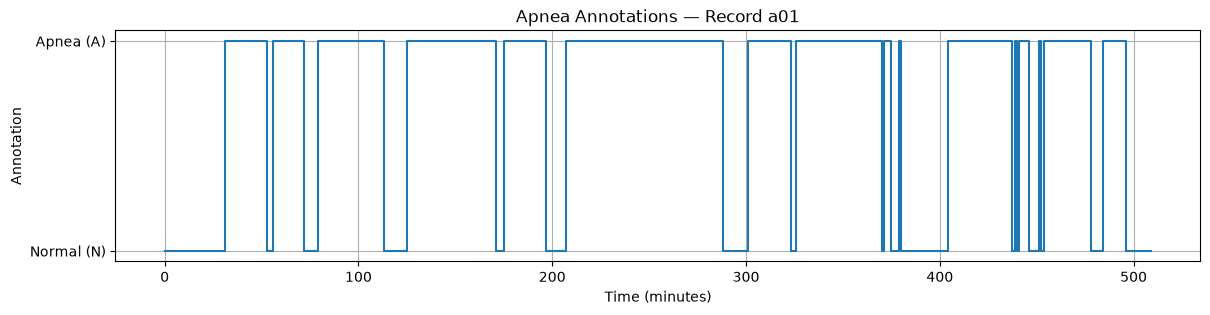

In [60]:
# Check that every minute has a single annotation label
minute_check = (
    rr_labeled.groupby("minute")["label"]
    .nunique()
)

print("Minutes containing multiple labels:",
      (minute_check > 1).sum())

# Plot annotation labels across time
plt.figure(figsize=(14, 3))

plt.step(
    ann_time / 60,
    np.where(ann_labels == "A", 1, 0),
    where="post"
)

plt.yticks([0, 1], ["Normal (N)", "Apnea (A)"])
plt.xlabel("Time (minutes)")
plt.ylabel("Annotation")
plt.title("Apnea Annotations — Record a01")
plt.grid()
plt.show()

In [62]:
print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)

print("\nTraining label distribution:")
print(pd.Series(y_train).value_counts())

print("\nValidation label distribution:")
print(pd.Series(y_val).value_counts())

print("\nTest label distribution:")
print(pd.Series(y_test).value_counts())

Training set: (4061, 6000, 1)
Validation set: (1528, 6000, 1)
Test set: (1449, 6000, 1)

Training label distribution:
1    2638
0    1423
Name: count, dtype: int64

Validation label distribution:
1    818
0    710
Name: count, dtype: int64

Test label distribution:
1    935
0    514
Name: count, dtype: int64


In [24]:
from pathlib import Path
import wfdb
import numpy as np
import pandas as pd
from scipy.signal import butter, sosfiltfilt

# Path relative to your notebooks folder
DATA_DIR = Path("../data/data/raw/apnea-ecg")

# List the patient IDs you downloaded.
# Example assumes you downloaded a01 through a15.
patient_ids = [f"a{i:02d}" for i in range(1, 16)]

for patient in patient_ids:
    base = DATA_DIR / patient

    print(
        patient,
        "ECG:", base.with_suffix(".dat").exists(),
        "Header:", base.with_suffix(".hea").exists(),
        "Annotations:", base.with_suffix(".apn").exists()
    )

a01 ECG: True Header: True Annotations: True
a02 ECG: True Header: True Annotations: True
a03 ECG: True Header: True Annotations: True
a04 ECG: True Header: True Annotations: True
a05 ECG: True Header: True Annotations: True
a06 ECG: True Header: True Annotations: True
a07 ECG: True Header: True Annotations: True
a08 ECG: True Header: True Annotations: True
a09 ECG: True Header: True Annotations: True
a10 ECG: True Header: True Annotations: True
a11 ECG: True Header: True Annotations: True
a12 ECG: True Header: True Annotations: True
a13 ECG: True Header: True Annotations: True
a14 ECG: True Header: True Annotations: True
a15 ECG: True Header: True Annotations: True


In [69]:
import wfdb
import numpy as np
import pandas as pd
from scipy.signal import butter, sosfiltfilt
from pathlib import Path

WINDOW_SECONDS = 60
TARGET_FS = 100
WINDOW_SAMPLES = WINDOW_SECONDS * TARGET_FS

# Bandpass filter: 0.5–40 Hz
sos = butter(
    4, [0.5, 40],
    btype="bandpass",
    fs=TARGET_FS,
    output="sos"
)

X_list = []
y_list = []
groups = []
segment_info = []
failed_patients = []

for patient in patient_ids:
    base = DATA_DIR / patient
    print(f"\nProcessing {patient}...")

    # Check that all required files exist
    if not all(
        base.with_suffix(ext).exists()
        for ext in [".dat", ".hea", ".apn"]
    ):
        print(f"Skipping {patient}: required file missing")
        failed_patients.append(patient)
        continue

    # Load the recording and annotations safely
    try:
        record = wfdb.rdrecord(str(base))
        annotation = wfdb.rdann(str(base), "apn")

    except Exception as e:
        print(f"Skipping {patient}: could not load recording")
        print(f"Reason: {type(e).__name__}: {e}")
        failed_patients.append(patient)
        continue

    try:
        ecg = record.p_signal[:, 0]
        fs = record.fs

        if not np.isclose(fs, TARGET_FS):
            print(f"Skipping {patient}: sampling rate is {fs} Hz")
            failed_patients.append(patient)
            continue

        # Filter ECG
        ecg_filtered = sosfiltfilt(sos, ecg)

        labels = np.asarray(annotation.symbol)

        # Use only complete minutes with corresponding annotations
        n_segments = min(
            len(ecg_filtered) // WINDOW_SAMPLES,
            len(labels)
        )

        patient_count = 0

        for minute in range(n_segments):
            label = labels[minute]

            if label not in ["A", "N"]:
                continue

            start = minute * WINDOW_SAMPLES
            end = start + WINDOW_SAMPLES

            segment = ecg_filtered[start:end]

            # Normalize the segment
            segment = (segment - np.mean(segment)) / (
                np.std(segment) + 1e-8
            )

            X_list.append(segment.astype(np.float32))
            y_list.append(1 if label == "A" else 0)
            groups.append(patient)

            segment_info.append({
                "patient": patient,
                "minute": minute,
                "label": label
            })

            patient_count += 1

        print(f"{patient}: successfully added {patient_count} segments")

    except Exception as e:
        print(f"Error processing {patient}: {type(e).__name__}: {e}")
        failed_patients.append(patient)

# Convert collected data to arrays
if len(X_list) == 0:
    raise ValueError(
        "No segments were created. Check the recording and annotation files."
    )

X = np.asarray(X_list, dtype=np.float32)[..., np.newaxis]
y = np.asarray(y_list, dtype=np.int32)
groups = np.asarray(groups)
metadata = pd.DataFrame(segment_info)

print("\n========== DATASET SUMMARY ==========")
print("X shape:", X.shape)
print("y shape:", y.shape)
print("Patients successfully used:", np.unique(groups))
print("Number of patients used:", len(np.unique(groups)))
print("Failed patients:", sorted(set(failed_patients)))

print("\nLabel counts:")
print(
    pd.Series(y)
    .map({0: "Normal", 1: "Apnea"})
    .value_counts()
)


Processing a01...
a01: successfully added 489 segments

Processing a02...
Skipping a02: could not load recording
Reason: ValueError: Samples were not loaded correctly

Processing a03...
a03: successfully added 519 segments

Processing a04...
a04: successfully added 492 segments

Processing a05...
a05: successfully added 453 segments

Processing a06...
a06: successfully added 509 segments

Processing a07...
a07: successfully added 510 segments

Processing a08...
a08: successfully added 500 segments

Processing a09...
a09: successfully added 495 segments

Processing a10...
a10: successfully added 516 segments

Processing a11...
a11: successfully added 466 segments

Processing a12...
a12: successfully added 577 segments

Processing a13...
a13: successfully added 494 segments

Processing a14...
a14: successfully added 509 segments

Processing a15...
a15: successfully added 509 segments

========== DATASET SUMMARY ==========
X shape: (7038, 6000, 1)
y shape: (7038,)
Patients successfully u

In [70]:
from sklearn.model_selection import GroupShuffleSplit
import numpy as np

# 20% of patients reserved for final testing
split1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_val_idx, test_idx = next(
    split1.split(X, y, groups=groups)
)

# 25% of remaining patients reserved for validation
split2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.25,
    random_state=42
)

train_rel, val_rel = next(
    split2.split(
        X[train_val_idx],
        y[train_val_idx],
        groups=groups[train_val_idx]
    )
)

train_idx = train_val_idx[train_rel]
val_idx = train_val_idx[val_rel]

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]

groups_train = groups[train_idx]
groups_val = groups[val_idx]
groups_test = groups[test_idx]

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

print("\nPatients in each split:")
print("Train:", np.unique(groups_train))
print("Validation:", np.unique(groups_val))
print("Test:", np.unique(groups_test))

# Confirm there is no patient overlap
assert set(groups_train).isdisjoint(set(groups_val))
assert set(groups_train).isdisjoint(set(groups_test))
assert set(groups_val).isdisjoint(set(groups_test))

print("\nPatient-level split verified.")

Training: (4061, 6000, 1)
Validation: (1528, 6000, 1)
Testing: (1449, 6000, 1)

Patients in each split:
Train: ['a04' 'a05' 'a06' 'a07' 'a09' 'a10' 'a12' 'a15']
Validation: ['a03' 'a08' 'a14']
Test: ['a01' 'a11' 'a13']

Patient-level split verified.


In [65]:
import pandas as pd

for name, labels in [
    ("Training", y_train),
    ("Validation", y_val),
    ("Testing", y_test)
]:
    print(f"\n{name} label counts:")
    print(
        pd.Series(labels)
        .map({0: "Normal", 1: "Apnea"})
        .value_counts()
    )


Training label counts:
Apnea     2638
Normal    1423
Name: count, dtype: int64

Validation label counts:
Apnea     818
Normal    710
Name: count, dtype: int64

Testing label counts:
Apnea     935
Normal    514
Name: count, dtype: int64


In [28]:
pip install tensorflow

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [71]:

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input, Conv1D, MaxPooling1D,
    GlobalAveragePooling1D, Dense, Dropout, BatchNormalization
)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

def build_cnn():
    model = Sequential([
        Input(shape=(6000, 1)),

        Conv1D(32, 7, padding="same", activation="relu"),
        BatchNormalization(),
        MaxPooling1D(4),

        Conv1D(64, 5, padding="same", activation="relu"),
        BatchNormalization(),
        MaxPooling1D(4),

        Conv1D(64, 3, padding="same", activation="relu"),
        GlobalAveragePooling1D(),

        Dense(32, activation="relu"),
        Dropout(0.2),
        Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.0003),
        loss="binary_crossentropy",
        metrics=[
            "accuracy",
            tf.keras.metrics.AUC(name="auc")
        ]
    )
    return model

model = build_cnn()
model.summary()


Model: "sequential_18"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv1d_54 (Conv1D)                   │ (None, 6000, 32)            │             256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 6000, 32)            │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d_36 (MaxPooling1D)      │ (None, 1500, 32)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_55 (Conv1D)                   │ (None, 1500, 64)            │          10,304 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_3                │ (None, 1500, 64)            │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d_37 (MaxPooling1D)      │ (None, 375, 64)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_56 (Conv1D)                   │ (None, 375, 64)             │          12,352 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling1d_18          │ (None, 64)                  │               0 │
│ (GlobalAveragePooling1D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_36 (Dense)                     │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_18 (Dropout)                 │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_37 (Dense)                     │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 25,409 (99.25 KB)

 Trainable params: 25,217 (98.50 KB)

 Non-trainable params: 192 (768.00 B)

In [72]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

model = build_cnn()

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),
    ModelCheckpoint(
        "/content/regularized_apnea_cnn.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=16,
    class_weight=class_weights,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/30
254/254 ━━━━━━━━━━━━━━━━━━━━ 70s 239ms/step - accuracy: 0.6868 - auc: 0.7444 - loss: 0.5972 - val_accuracy: 0.5360 - val_auc: 0.7026 - val_loss: 0.6788
Epoch 2/30
254/254 ━━━━━━━━━━━━━━━━━━━━ 59s 230ms/step - accuracy: 0.7245 - auc: 0.7969 - loss: 0.5455 - val_accuracy: 0.6597 - val_auc: 0.7887 - val_loss: 0.6141
Epoch 3/30
254/254 ━━━━━━━━━━━━━━━━━━━━ 59s 231ms/step - accuracy: 0.7343 - auc: 0.8107 - loss: 0.5314 - val_accuracy: 0.7395 - val_auc: 0.8430 - val_loss: 0.5899
Epoch 4/30
254/254 ━━━━━━━━━━━━━━━━━━━━ 57s 223ms/step - accuracy: 0.7432 - auc: 0.8228 - loss: 0.5197 - val_accuracy: 0.7376 - val_auc: 0.8371 - val_loss: 0.5405
Epoch 5/30
254/254 ━━━━━━━━━━━━━━━━━━━━ 58s 229ms/step - accuracy: 0.7565 - auc: 0.8352 - loss: 0.5028 - val_accuracy: 0.6682 - val_auc: 0.8182 - val_loss: 0.5747
Epoch 6/30
254/254 ━━━━━━━━━━━━━━━━━━━━ 59s 233ms/step - accuracy: 0.7643 - auc: 0.8488 - loss: 0.4849 - val_accuracy: 0.7048 - val_auc: 0.8248 - val_loss: 0.5443
Epoch 7/30
254/254 ━━━

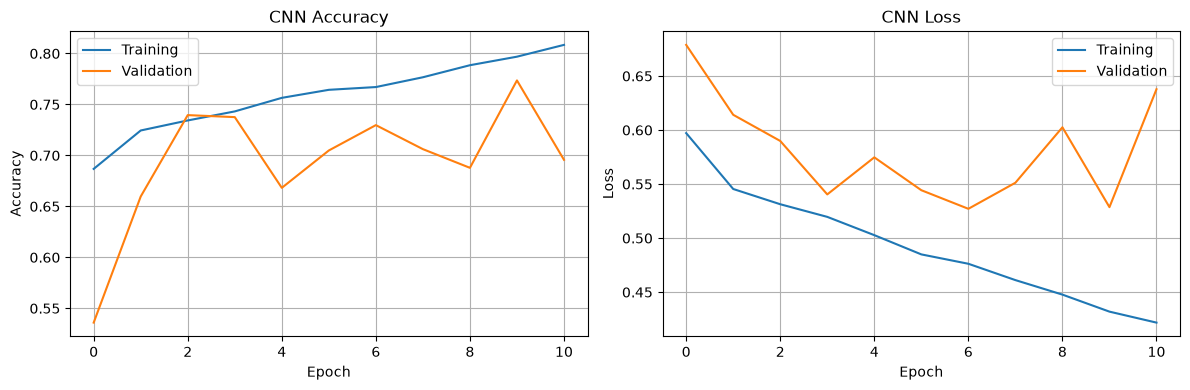

In [73]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [82]:
test_results = model.evaluate(
    X_test,
    y_test,
    verbose=1,
    return_dict=True
)

print(f"Test Loss:     {test_results['loss']:.4f}")
print(f"Test Accuracy: {test_results['accuracy']:.4f}")
print(f"Test ROC-AUC:  {test_results['auc']:.4f}")

46/46 ━━━━━━━━━━━━━━━━━━━━ 3s 65ms/step - accuracy: 0.7081 - auc: 0.8647 - loss: 0.5004
Test Loss:     0.5004
Test Accuracy: 0.7081
Test ROC-AUC:  0.8647


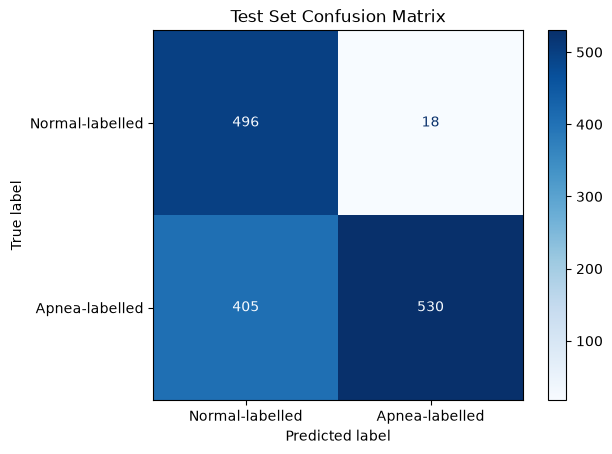

                 precision    recall  f1-score   support

Normal-labelled       0.55      0.96      0.70       514
 Apnea-labelled       0.97      0.57      0.71       935

       accuracy                           0.71      1449
      macro avg       0.76      0.77      0.71      1449
   weighted avg       0.82      0.71      0.71      1449

ROC-AUC: 0.8649


In [76]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_auc_score
)

# Predict probabilities on the test set
y_prob = model.predict(X_test, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal-labelled", "Apnea-labelled"]
).plot(cmap="Blues")

plt.title("Test Set Confusion Matrix")
plt.show()

# Classification report
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Normal-labelled", "Apnea-labelled"],
    zero_division=0
))

# ROC-AUC
if len(np.unique(y_test)) == 2:
    print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

Actual labels: (array([0, 1], dtype=int32), array([514, 935]))
Predicted labels: (array([0, 1]), array([901, 548]))

Normal-labelled
Mean predicted apnea probability: 0.3313
Minimum: 0.1315
Maximum: 0.9143

Apnea-labelled
Mean predicted apnea probability: 0.6259
Minimum: 0.1613
Maximum: 0.9553


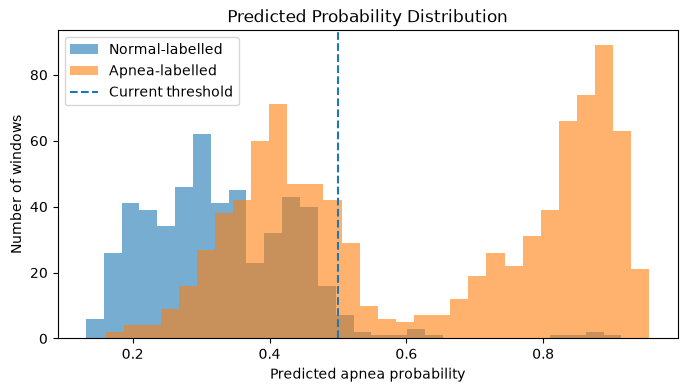

In [77]:
import numpy as np
import matplotlib.pyplot as plt

print("Actual labels:", np.unique(y_test, return_counts=True))
print("Predicted labels:", np.unique(y_pred, return_counts=True))

for label, name in [(0, "Normal-labelled"), (1, "Apnea-labelled")]:
    probs = y_prob[np.asarray(y_test).ravel() == label]

    print(f"\n{name}")
    print("Mean predicted apnea probability:", round(float(probs.mean()), 4))
    print("Minimum:", round(float(probs.min()), 4))
    print("Maximum:", round(float(probs.max()), 4))

plt.figure(figsize=(8, 4))
plt.hist(y_prob[np.asarray(y_test).ravel() == 0],
         bins=30, alpha=0.6, label="Normal-labelled")
plt.hist(y_prob[np.asarray(y_test).ravel() == 1],
         bins=30, alpha=0.6, label="Apnea-labelled")
plt.axvline(0.5, linestyle="--", label="Current threshold")
plt.xlabel("Predicted apnea probability")
plt.ylabel("Number of windows")
plt.title("Predicted Probability Distribution")
plt.legend()
plt.show()

In [78]:
import numpy as np

for name, X, y in [
    ("Train", X_train, y_train),
    ("Validation", X_val, y_val),
    ("Test", X_test, y_test)
]:
    probabilities = model.predict(X, verbose=0).ravel()
    labels = np.asarray(y).ravel()

    print(f"\n--- {name} ---")
    print("Actual label counts:", np.unique(labels, return_counts=True))
    print("Probability minimum:", round(float(probabilities.min()), 4))
    print("Probability maximum:", round(float(probabilities.max()), 4))
    print("Probability mean:", round(float(probabilities.mean()), 4))
    print("Probability standard deviation:",
          round(float(probabilities.std()), 4))


--- Train ---
Actual label counts: (array([0, 1], dtype=int32), array([1423, 2638]))
Probability minimum: 0.0784
Probability maximum: 0.9991
Probability mean: 0.6255
Probability standard deviation: 0.2915

--- Validation ---
Actual label counts: (array([0, 1], dtype=int32), array([710, 818]))
Probability minimum: 0.1189
Probability maximum: 0.9851
Probability mean: 0.5311
Probability standard deviation: 0.2776

--- Test ---
Actual label counts: (array([0, 1], dtype=int32), array([514, 935]))
Probability minimum: 0.1315
Probability maximum: 0.9553
Probability mean: 0.5214
Probability standard deviation: 0.24


In [54]:
import numpy as np

for name, X, y in [
    ("Train", X_train, y_train),
    ("Validation", X_val, y_val),
    ("Test", X_test, y_test)
]:
    X_arr = np.asarray(X)
    y_arr = np.asarray(y).ravel()

    print(f"\n--- {name} ---")
    print("Shape:", X_arr.shape)
    print("Overall minimum:", round(float(X_arr.min()), 4))
    print("Overall maximum:", round(float(X_arr.max()), 4))
    print("Overall mean:", round(float(X_arr.mean()), 4))
    print("Overall standard deviation:", round(float(X_arr.std()), 4))

    for label in [0, 1]:
        group = X_arr[y_arr == label]
        if len(group) > 0:
            print(
                f"Label {label}:",
                "mean =", round(float(group.mean()), 4),
                "| std =", round(float(group.std()), 4)
            )


--- Train ---
Shape: (4061, 6000, 1)
Overall minimum: -27.0176
Overall maximum: 27.4601
Overall mean: -0.0
Overall standard deviation: 1.0
Label 0: mean = 0.0 | std = 1.0
Label 1: mean = -0.0 | std = 1.0

--- Validation ---
Shape: (1528, 6000, 1)
Overall minimum: -10.8956
Overall maximum: 11.0414
Overall mean: -0.0
Overall standard deviation: 1.0
Label 0: mean = -0.0 | std = 1.0
Label 1: mean = -0.0 | std = 1.0

--- Test ---
Shape: (1449, 6000, 1)
Overall minimum: -9.0834
Overall maximum: 13.9369
Overall mean: 0.0
Overall standard deviation: 1.0
Label 0: mean = -0.0 | std = 1.0
Label 1: mean = 0.0 | std = 1.0


In [81]:
import numpy as np
from sklearn.metrics import (
    roc_auc_score,
    classification_report,
    confusion_matrix
)

val_prob = model.predict(X_val, verbose=0).ravel()
val_true = np.asarray(y_val).ravel().astype(int)

print("Validation ROC-AUC:", round(roc_auc_score(val_true, val_prob), 4))

for label, name in [(0, "Normal"), (1, "Apnea")]:
    probs = val_prob[val_true == label]

    print(f"\n{name} windows:")
    print("Count:", len(probs))
    print("Mean probability:", round(float(probs.mean()), 4))
    print("Median probability:", round(float(np.median(probs)), 4))
    print("Minimum:", round(float(probs.min()), 4))
    print("Maximum:", round(float(probs.max()), 4))

val_pred = (val_prob >= 0.5).astype(int)

print("\nConfusion matrix:")
print(confusion_matrix(val_true, val_pred))

print("\nClassification report:")
print(classification_report(
    val_true,
    val_pred,
    labels=[0, 1],
    target_names=["Normal", "Apnea"],
    zero_division=0
))

Validation ROC-AUC: 0.8272

Normal windows:
Count: 710
Mean probability: 0.3699
Median probability: 0.2774
Minimum: 0.1189
Maximum: 0.9851

Apnea windows:
Count: 818
Mean probability: 0.6711
Median probability: 0.7489
Minimum: 0.1563
Maximum: 0.9814

Confusion matrix:
[[537 173]
 [240 578]]

Classification report:
              precision    recall  f1-score   support

      Normal       0.69      0.76      0.72       710
       Apnea       0.77      0.71      0.74       818

    accuracy                           0.73      1528
   macro avg       0.73      0.73      0.73      1528
weighted avg       0.73      0.73      0.73      1528



In [80]:
print("Epochs:", len(history.history["loss"]))
print("Final training loss:", history.history["loss"][-1])
print("Final validation loss:", history.history["val_loss"][-1])
print("Best validation loss:", min(history.history["val_loss"]))
print("Best validation accuracy:", max(history.history["val_accuracy"]))

Epochs: 11
Final training loss: 0.42182672023773193
Final validation loss: 0.6377690434455872
Best validation loss: 0.5271354913711548
Best validation accuracy: 0.7735602259635925


In [83]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

# Use validation probabilities, not test probabilities
val_prob = model.predict(X_val, verbose=0).ravel()

for threshold in [0.5, 0.45, 0.4, 0.35, 0.3]:
    val_pred = (val_prob >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print(confusion_matrix(y_val, val_pred))
    print(classification_report(
        y_val,
        val_pred,
        target_names=["Normal", "Apnea"],
        zero_division=0
    ))


Threshold: 0.5
[[537 173]
 [240 578]]
              precision    recall  f1-score   support

      Normal       0.69      0.76      0.72       710
       Apnea       0.77      0.71      0.74       818

    accuracy                           0.73      1528
   macro avg       0.73      0.73      0.73      1528
weighted avg       0.73      0.73      0.73      1528


Threshold: 0.45
[[514 196]
 [193 625]]
              precision    recall  f1-score   support

      Normal       0.73      0.72      0.73       710
       Apnea       0.76      0.76      0.76       818

    accuracy                           0.75      1528
   macro avg       0.74      0.74      0.74      1528
weighted avg       0.75      0.75      0.75      1528


Threshold: 0.4
[[482 228]
 [156 662]]
              precision    recall  f1-score   support

      Normal       0.76      0.68      0.72       710
       Apnea       0.74      0.81      0.78       818

    accuracy                           0.75      1528
   macro a

In [89]:
threshold = 0.40

y_test_prob = model.predict(X_test, verbose=0).ravel()
y_test_pred = (y_test_prob >= threshold).astype(int)

from sklearn.metrics import confusion_matrix, classification_report

print("Threshold:", threshold)
print(confusion_matrix(y_test, y_test_pred))
print(classification_report(
    y_test,
    y_test_pred,
    target_names=["Normal", "Apnea"]
))

Threshold: 0.4
[[375 139]
 [205 730]]
              precision    recall  f1-score   support

      Normal       0.65      0.73      0.69       514
       Apnea       0.84      0.78      0.81       935

    accuracy                           0.76      1449
   macro avg       0.74      0.76      0.75      1449
weighted avg       0.77      0.76      0.77      1449



In [90]:
model.save("apnea_cnn.keras")

In [91]:
threshold = 0.40  # Example only; finalize using validation results

import json

with open("model_config.json", "w") as f:
    json.dump({"threshold": threshold}, f)

In [93]:
import json
import numpy as np
from tensorflow.keras.models import load_model

model = load_model("apnea_cnn.keras")

with open("model_config.json", "r") as f:
    threshold = json.load(f)["threshold"]

def predict_apnea(ecg_window):
    # ecg_window must be a preprocessed 60-second ECG window
    x = np.asarray(ecg_window, dtype=np.float32).reshape(1, 6000, 1)

    probability = float(model.predict(x, verbose=0)[0][0])
    label = "Apnea" if probability >= threshold else "Normal"

    return label, probability

In [94]:
window = X_test[0].squeeze()

label, probability = predict_apnea(window)

print("Prediction:", label)
print(f"Apnea probability: {probability:.2%}")

Prediction: Apnea
Apnea probability: 60.55%


In [95]:
for i in range(10):
    window = X_test[i].squeeze()

    prediction, probability = predict_apnea(window)
    actual = "Apnea" if y_test[i] == 1 else "Normal"

    print(
        f"Window {i+1}: "
        f"Actual={actual}, "
        f"Predicted={prediction}, "
        f"Score={probability:.2%}"
    )

Window 1: Actual=Normal, Predicted=Apnea, Score=60.55%
Window 2: Actual=Normal, Predicted=Normal, Score=38.28%
Window 3: Actual=Normal, Predicted=Apnea, Score=41.30%
Window 4: Actual=Normal, Predicted=Normal, Score=29.88%
Window 5: Actual=Normal, Predicted=Normal, Score=32.19%
Window 6: Actual=Normal, Predicted=Normal, Score=39.29%
Window 7: Actual=Normal, Predicted=Normal, Score=35.47%
Window 8: Actual=Normal, Predicted=Normal, Score=27.10%
Window 9: Actual=Normal, Predicted=Normal, Score=30.14%
Window 10: Actual=Normal, Predicted=Normal, Score=37.54%


In [96]:
import numpy as np
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    roc_auc_score
)

y_true = np.asarray(y_test).astype(int).ravel()
y_prob = model.predict(X_test, verbose=0).ravel()
y_pred = (y_prob >= threshold).astype(int)

print("Threshold:", threshold)
print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("\nConfusion Matrix:\n", confusion_matrix(y_true, y_pred))
print("\nClassification Report:\n",
      classification_report(
          y_true, y_pred,
          target_names=["Normal", "Apnea"],
          zero_division=0
      ))
print("ROC-AUC:", round(roc_auc_score(y_true, y_prob), 4))

Threshold: 0.4
Accuracy: 0.7626

Confusion Matrix:
 [[375 139]
 [205 730]]

Classification Report:
               precision    recall  f1-score   support

      Normal       0.65      0.73      0.69       514
       Apnea       0.84      0.78      0.81       935

    accuracy                           0.76      1449
   macro avg       0.74      0.76      0.75      1449
weighted avg       0.77      0.76      0.77      1449

ROC-AUC: 0.8649


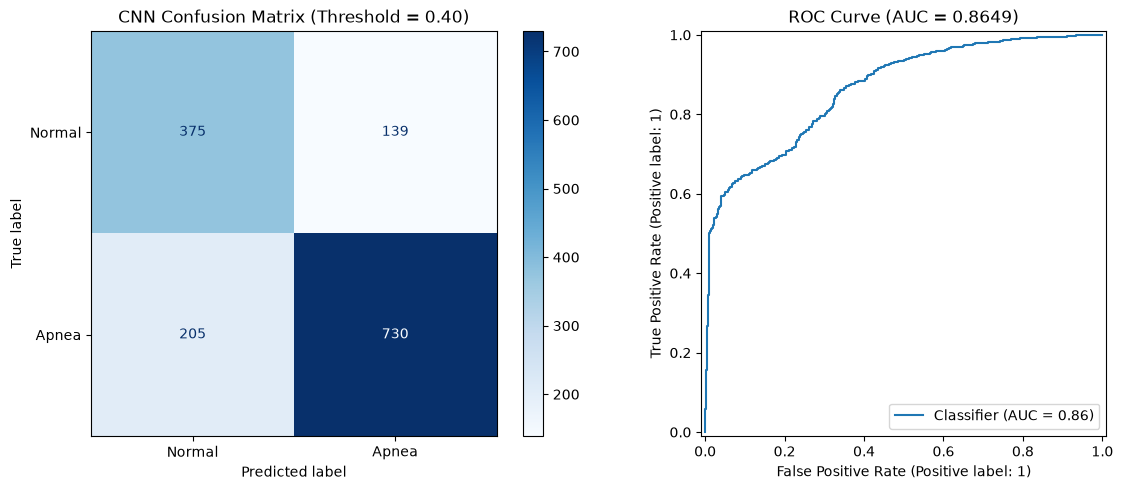

In [97]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    display_labels=["Normal", "Apnea"],
    ax=axes[0],
    cmap="Blues"
)
axes[0].set_title("CNN Confusion Matrix (Threshold = 0.40)")

RocCurveDisplay.from_predictions(
    y_true,
    y_prob,
    ax=axes[1]
)
axes[1].set_title(f"ROC Curve (AUC = {roc_auc_score(y_true, y_prob):.4f})")

plt.tight_layout()
plt.savefig("cnn_evaluation_plots.png", dpi=300, bbox_inches="tight")
plt.show()

In [98]:
from sklearn.metrics import classification_report

report = classification_report(
    y_true,
    y_pred,
    target_names=["Normal", "Apnea"],
    zero_division=0
)

with open("classification_report.txt", "w") as f:
    f.write("ECG Sleep Apnea CNN Evaluation\n")
    f.write("Threshold: 0.40\n")
    f.write("Test Accuracy: 76.26%\n")
    f.write("Test ROC-AUC: 0.8649\n\n")
    f.write(report)

print("Classification report saved!")

Classification report saved!


In [99]:
import os
import json
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score

# Create a folder for final model outputs
os.makedirs("../results/final_model", exist_ok=True)

output_dir = "../results/final_model"

# 1. Save trained CNN
model.save(os.path.join(output_dir, "apnea_cnn.keras"))

# 2. Save the selected threshold
with open(os.path.join(output_dir, "model_config.json"), "w") as f:
    json.dump({"threshold": float(threshold)}, f, indent=4)

# 3. Save test predictions and actual labels
np.savez(
    os.path.join(output_dir, "test_predictions.npz"),
    y_true=y_true,
    y_pred=y_pred,
    y_prob=y_prob
)

# 4. Save evaluation report
report = classification_report(
    y_true, y_pred,
    target_names=["Normal", "Apnea"],
    zero_division=0
)

with open(os.path.join(output_dir, "evaluation_report.txt"), "w") as f:
    f.write(f"Threshold: {threshold}\n")
    f.write(f"Test accuracy: {(y_true == y_pred).mean():.4f}\n")
    f.write(f"ROC-AUC: {roc_auc_score(y_true, y_prob):.4f}\n\n")
    f.write("Confusion matrix:\n")
    f.write(str(confusion_matrix(y_true, y_pred)))
    f.write("\n\nClassification report:\n")
    f.write(report)

print("Saved model and evaluation files to:", output_dir)
print(os.listdir(output_dir))

Saved model and evaluation files to: ../results/final_model
['apnea_cnn.keras', 'evaluation_report.txt', 'model_config.json', 'test_predictions.npz']


In [100]:
import os
import json
import numpy as np
from tensorflow.keras.models import load_model

output_dir = "../results/final_model"

model = load_model(
    os.path.join(output_dir, "apnea_cnn.keras")
)

with open(os.path.join(output_dir, "model_config.json"), "r") as f:
    threshold = json.load(f)["threshold"]

print("Model loaded successfully!")
print("Decision threshold:", threshold)

Model loaded successfully!
Decision threshold: 0.4


In [102]:
def predict_apnea(ecg_window):
    """
    ecg_window: one 60-second ECG window,
                already filtered and normalized as during training.
    """
    x = np.asarray(ecg_window, dtype=np.float32).reshape(1, 6000, 1)

    probability = float(model.predict(x, verbose=0)[0][0])
    prediction = "Apnea" if probability >= threshold else "Normal"

    print("Prediction:", prediction)
    print(f"Apnea score: {probability:.2%}")

    return prediction, probability

In [105]:
prediction, probability = predict_apnea(X_test[0].squeeze())

Prediction: Apnea
Apnea score: 60.55%


# ECG-Based Sleep Apnea Detection Using CNN

## 1. Project Overview
The project aims to classify ECG signal segments into Normal and Apnea classes using a Convolutional Neural Network (CNN).

## 2. Signal Preprocessing
- ECG signals are sampled at 100 Hz.
- A Butterworth bandpass filter (0.5–40 Hz) is applied to reduce unwanted noise.
- Signals are divided into 60-second windows containing 6,000 samples.
- Each window is normalized before being supplied to the CNN.
- Heart rate and RR intervals are extracted from the ECG signals.

## 3. Label Generation and Dataset Splitting
Apnea annotations are mapped to the corresponding ECG windows to generate binary labels: Normal (0) and Apnea (1). The dataset is split at the patient level into training, validation, and test sets to reduce patient leakage.

## 4. CNN Model
The model uses multiple one-dimensional convolutional layers to learn temporal features from ECG segments, followed by global average pooling and dense layers for binary classification. Batch normalization and dropout are used to support training and reduce overfitting.

## 5. Test Results
- Accuracy: 76.26%
- ROC-AUC: 0.8649
- Apnea precision: 84%
- Apnea recall: 78%
- Apnea F1-score: 81%

## 6. Limitations
The model is an experimental academic prototype. Performance may vary across patients and datasets. It has not been clinically validated and should not be used for medical diagnosis.


Model loaded successfully!
Configuration: {'threshold': 0.4}

SAMPLE PREDICTIONS
-----------------------------------------------------------------
Window 01 | Actual: Normal | Predicted: Apnea  | Apnea score: 60.55% | INCORRECT
Window 02 | Actual: Normal | Predicted: Normal | Apnea score: 38.28% | CORRECT
Window 03 | Actual: Normal | Predicted: Apnea  | Apnea score: 41.30% | INCORRECT
Window 04 | Actual: Normal | Predicted: Normal | Apnea score: 29.88% | CORRECT
Window 05 | Actual: Normal | Predicted: Normal | Apnea score: 32.19% | CORRECT
Window 06 | Actual: Normal | Predicted: Normal | Apnea score: 39.29% | CORRECT
Window 07 | Actual: Normal | Predicted: Normal | Apnea score: 35.47% | CORRECT
Window 08 | Actual: Normal | Predicted: Normal | Apnea score: 27.10% | CORRECT
Window 09 | Actual: Normal | Predicted: Normal | Apnea score: 30.14% | CORRECT
Window 10 | Actual: Normal | Predicted: Normal | Apnea score: 37.54% | CORRECT

OVERALL TEST RESULTS
-------------------------------------

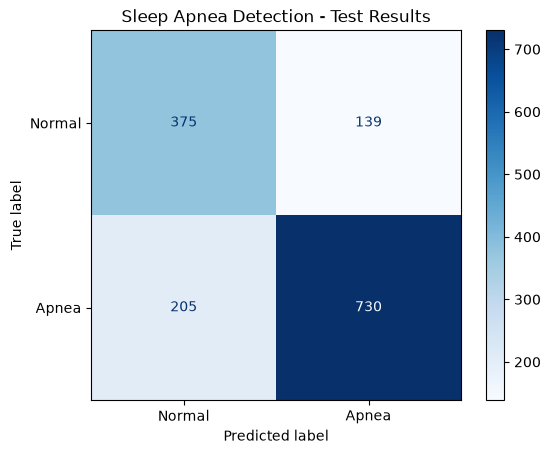

In [106]:
import numpy as np
import tensorflow as tf
import json
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, roc_auc_score, ConfusionMatrixDisplay
)

# 1. Load the saved model
model = tf.keras.models.load_model(
    "../results/final_model/apnea_cnn.keras"
)

# 2. Load the threshold saved for the model
with open("../results/final_model/model_config.json", "r") as f:
    config = json.load(f)

print("Model loaded successfully!")
print("Configuration:", config)

# 3. Use your existing held-out test data
# X_test should have shape (number_of_windows, 6000, 1)
# y_test should contain 0 = Normal and 1 = Apnea

# Predict probabilities
probabilities = model.predict(X_test, verbose=0).ravel()

# Use the threshold stored in your configuration.
# Change the key below if your JSON uses a different key.
threshold = config.get("threshold", 0.40)

predictions = (probabilities >= threshold).astype(int)

# 4. Show 10 sample predictions
print("\nSAMPLE PREDICTIONS")
print("-" * 65)

for i in range(min(10, len(y_test))):
    actual = "Apnea" if int(y_test[i]) == 1 else "Normal"
    predicted = "Apnea" if predictions[i] == 1 else "Normal"
    status = "CORRECT" if int(y_test[i]) == predictions[i] else "INCORRECT"

    print(
        f"Window {i+1:02d} | "
        f"Actual: {actual:6s} | "
        f"Predicted: {predicted:6s} | "
        f"Apnea score: {probabilities[i]*100:5.2f}% | "
        f"{status}"
    )

# 5. Overall evaluation
print("\nOVERALL TEST RESULTS")
print("-" * 65)
print(f"Test accuracy: {accuracy_score(y_test, predictions)*100:.2f}%")
print(f"ROC-AUC:       {roc_auc_score(y_test, probabilities):.4f}")
print("\nClassification Report:")
print(classification_report(
    y_test, predictions,
    labels=[0, 1],
    target_names=["Normal", "Apnea"],
    zero_division=0
))

# 6. Display the confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, predictions,
    labels=[0, 1],
    display_labels=["Normal", "Apnea"],
    cmap="Blues"
)
plt.title("Sleep Apnea Detection - Test Results")
plt.show()